In [1]:
import pandas as pd
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn import preprocessing
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression, ElasticNetCV, ElasticNet, Ridge, Lasso, HuberRegressor, Lars, TheilSenRegressor, SGDRegressor, SGDClassifier, LassoLars, LassoLarsIC
from sklearn.linear_model import OrthogonalMatchingPursuit, ARDRegression, BayesianRidge, TweedieRegressor, Perceptron, PassiveAggressiveClassifier, RidgeClassifier
import statsmodels.api as sm
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report, average_precision_score
from sklearn.pipeline import Pipeline
from statsmodels.formula.api import mnlogit
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.metrics import balanced_accuracy_score, PrecisionRecallDisplay
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.svm import LinearSVC, LinearSVR, SVC, SVR, NuSVR, NuSVC
from sklearn import svm, tree
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, plot_tree, DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor, ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve, auc
from sklearn.metrics import RocCurveDisplay
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go
from sklearn.ensemble import AdaBoostClassifier

## AdaBoostClassifier (Adaptive Boosting) — алгоритм ансамблевого обучения в scikit‑learn (sklearn.ensemble), который последовательно объединяет «слабые» модели (обычно — деревья решений малой глубины) в сильную композицию.

### Как работает:
1. Инициализация
- Всем объектам обучающей выборки присваиваются равные веса: w = 1 / N, где N — число объектов
  
2. Обучение первого «слабого» классификатора
- Модель обучается на взвешенной выборке.

3. Вычисление ошибки и обновление весов
- Для неверно классифицированных объектов веса увеличиваются.
- Вес нового классификатора (αt) зависит от его точности.
  
4. Повторение
- Следующий классификатор обучается на обновлённой выборке (с акцентом на «сложные» объекты).

5. Финальный прогноз
- Сумма предсказаний всех классификаторов с весами αt.

### Преимущества:
- Высокая точность - Часто превосходит одиночные модели за счёт ансамблевого подхода.
- Простота настройки - Минимальное число гиперпараметров.
- Устойчивость к переобучению - При разумном n_estimators и learning_rate.
- Интерпретируемость - Можно анализировать важность признаков и вклад отдельных моделей.
- Работа с разными типами моделей - В качестве estimator можно использовать любые классификаторы с поддержкой весов (sample_weight).

### Недостатки:
- Чувствительность к шуму и выбросам - Ошибки на «сложных» объектах могут усиливаться.
- Риск переобучения - При большом n_estimators или сложных базовых моделях.
- Медленное обучение - Последовательное обучение моделей требует времени.
- Ограниченная гибкость - Менее настраиваемый, чем XGBoost/LightGBM.
- Требование к поддержке весов - Базовая модель должна уметь работать с sample_weight.

### Когда использовать:
- Нужно быстро получить качественный baseline — простая настройка, хорошая точность «из коробки».
- Данные не содержат много шума и выбросов — AdaBoost чувствителен к аномалиям.
- Важна интерпретируемость — можно анализировать важность признаков.
- Есть время на обучение — последовательный алгоритм медленнее, чем параллельные ансамбли.
- Требуется совместимость со scikit‑learn — полная интеграция с пайплайнами и кросс‑валидацией.

In [2]:
db_null = pd.read_csv('D:/!РАБОТА/Statistic/DB/Mall_Customers.csv')
db_null = db_null.drop(['CustomerID'], axis=1)
db_onehot = db_null.copy()
db_onehot = db_onehot.astype({'Genre': 'category'})
encoder = OneHotEncoder(drop = 'first')
encoded_data = encoder.fit_transform(db_onehot[['Genre']]).toarray()
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['Genre']))
db_onehot = pd.concat([db_onehot, encoded_df], axis = 1)
db_onehot.drop('Genre', axis = 1, inplace = True)
db_onehot

,Age,Annual Income (k$),Spending Score (1-100),Genre_Male
0,19,15,39,1.0
1,21,15,81,1.0
2,20,16,6,0.0
3,23,16,77,0.0
4,31,17,40,0.0
...,...,...,...,...
195,35,120,79,0.0
196,45,126,28,0.0
197,32,126,74,1.0
198,32,137,18,1.0


## GridSearch - кросс-валидация оптимальных гиперпараметров модели:

In [13]:
# GridSearch для поиска гиперпараметров для модели AdaBoostClassifier
x = db_onehot[['Annual Income (k$)', 'Age', 'Genre_Male']]
y = db_onehot['Spending Score (1-100)']

binned = pd.cut(y, bins=[0, 60, 100], labels=['0', '1'], right=True) # разбиение зависимой переменной на диапазоны от 0 до 60 и от 61 до 100 процентов

db_logreg = db_onehot.assign(Score = binned)

x = db_logreg[['Age', 'Annual Income (k$)']]
y = db_logreg['Score']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1,  random_state=42, stratify = y, shuffle = True)

param_grid = {
    'n_estimators' : [43, 44, 45],                                 # Количество деревьев в лесу
    'learning_rate' : [0.54, 0.55, 0.56],                        # Шаг обучения
}

grid_search = GridSearchCV(AdaBoostClassifier(random_state = 42), param_grid, cv=3, verbose = 1, scoring='accuracy', n_jobs = -1)
grid_search.fit(x_train, y_train)
print("Лучшие параметры:", grid_search.best_params_)
print("Лучший accuracy:", -grid_search.best_score_)
best_model = grid_search.best_estimator_
print(best_model)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Лучшие параметры: {'learning_rate': 0.55, 'n_estimators': 44}
Лучший accuracy: -0.8722222222222222
AdaBoostClassifier(learning_rate=0.55, n_estimators=44, random_state=42)


In [14]:
results_df = pd.DataFrame(grid_search.cv_results_)
# results_df
display(results_df[[
    'mean_test_score',
    'std_test_score'
]].sort_values('mean_test_score', ascending=False).head(10))

,mean_test_score,std_test_score
4,0.872222,0.007857
7,0.872222,0.007857
1,0.866667,0.013608
3,0.866667,0.013608
5,0.866667,0.013608
6,0.866667,0.013608
8,0.866667,0.013608
0,0.855556,0.028328
2,0.855556,0.028328


In [18]:
# Построим модель на основе AdaBoostClassifier
x = db_onehot[['Annual Income (k$)', 'Age', 'Genre_Male']]
y = db_onehot['Spending Score (1-100)']

binned = pd.cut(y, bins=[0, 60, 100], labels=['0', '1'], right=True) # разбиение зависимой переменной на диапазоны от 0 до 60 и от 61 до 100 процентов

db_logreg = db_onehot.assign(Score = binned)

x = db_logreg[['Age', 'Annual Income (k$)']]
y = db_logreg['Score']
x = x.to_numpy()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1,  random_state=42, stratify = y, shuffle = True)

model_AdaBoostClassifier = AdaBoostClassifier(
    learning_rate = 0.55,
    n_estimators = 44,
    random_state = 42)
    
model_AdaBoostClassifier.fit(x_train, y_train)
y_pred = model_AdaBoostClassifier.predict(x_test)  # метки классов (0/1)
y_pred_proba = model_AdaBoostClassifier.predict_proba(x_test)[:, 1] # вероятност положительных классов (1)
y_pred_proba_0 = model_AdaBoostClassifier.predict_proba(x_test)[:, 0] # вероятност отрицательных классов (0)

acc_1 = accuracy_score(y_test, y_pred)
print(f"Точность: {acc_1:.4f}")
print('---------------------------------')
print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred))
print('---------------------------------')
print("Отчёт по классификации:")
print(classification_report(y_test, y_pred, zero_division=0, target_names=['0-60% [0]' , '61-100% [1]'])) # Значение, возвращаемое при делении на ноль
print('---------------------------------')
auc_1 = roc_auc_score(y_test, y_pred_proba) # Все строки второго столбца
print(f"ROC‑AUC: {auc_1:.4f}")

Точность: 0.9000
---------------------------------
Матрица ошибок:
[[12  2]
 [ 0  6]]
---------------------------------
Отчёт по классификации:
              precision    recall  f1-score   support

   0-60% [0]       1.00      0.86      0.92        14
 61-100% [1]       0.75      1.00      0.86         6

    accuracy                           0.90        20
   macro avg       0.88      0.93      0.89        20
weighted avg       0.93      0.90      0.90        20

---------------------------------
ROC‑AUC: 0.9167


## Интерпретация метрик качества модели:

Как выбирать, на что смотреть:

1.	Если классы сбалансированы (примерно одинаковое число примеров):
-	Можно ориентироваться на macro avg — он честно усредняет по классам.
-	weighted avg будет близок к macro avg.
2.	Если классы несбалансированы:
-	weighted avg лучше отражает «общее» качество модели.
-	macro avg покажет, как модель работает с малыми классами (которые могут быть важны).
3.	Если один класс критически важен (например, «болезнь» в диагностике):
-	Смотрите precision и recall именно для этого класса.
-	F1 для этого класса — хороший компромисс.
4.	Если нужно сравнить модели:
-	Используйте weighted avg F1 как общую метрику.
-	Дополнительно проверьте macro avg, чтобы убедиться, что модель не «забывает» малые классы.

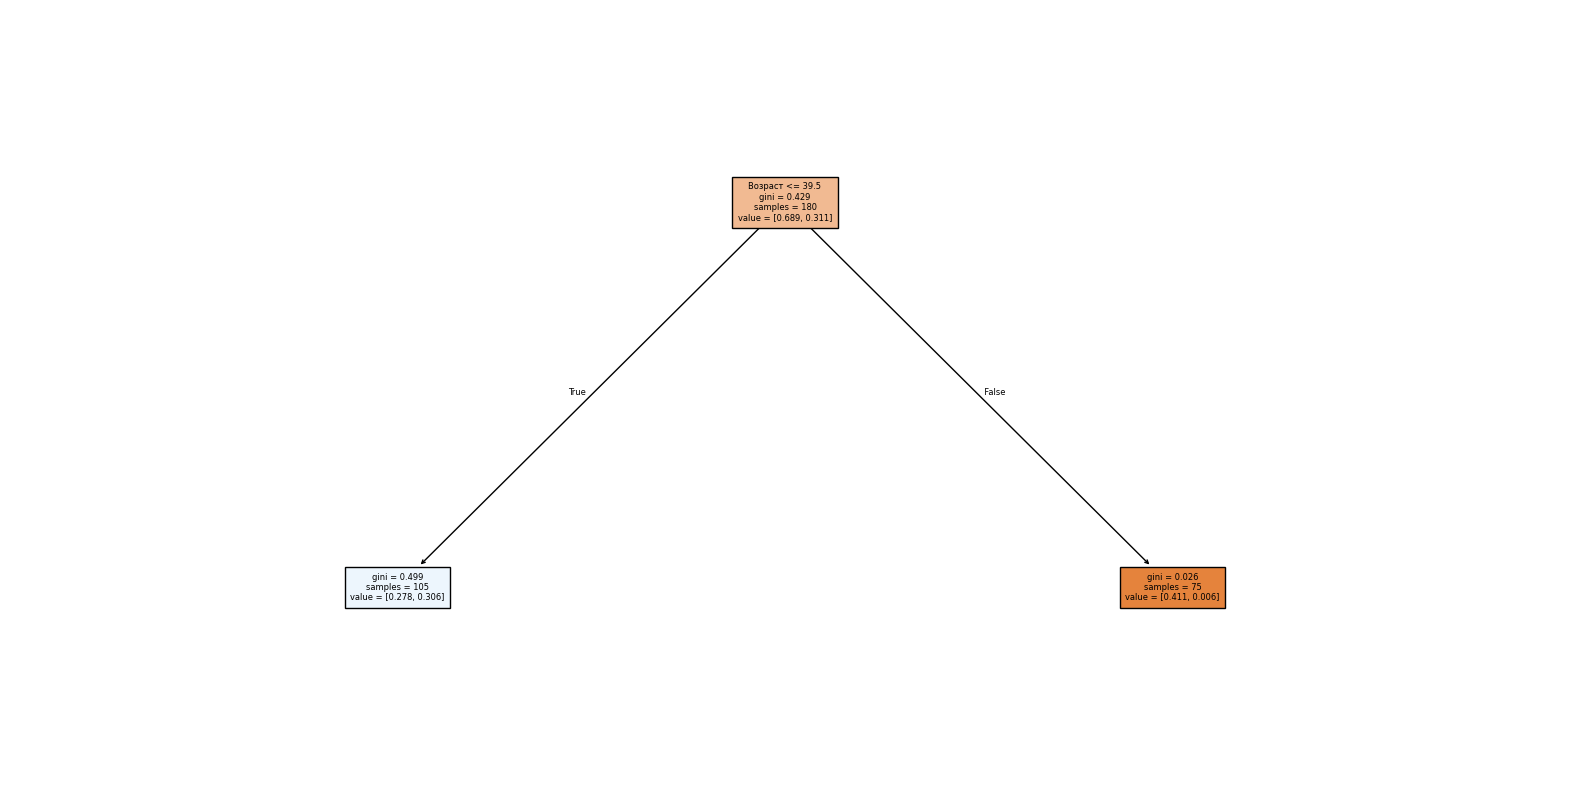

In [36]:
# Визуализация дерева
plt.figure(figsize=(20, 10))
plot_tree(
    model_AdaBoostClassifier[0],   # для бинарной классификации: [номер_итерации, номер_класса]
    feature_names=['Возраст', 'Доход'],
    filled=True,
    rounded=False,
    fontsize=6
)
plt.show()

#### Важность признаков:

In [53]:
print("Важность признаков:", model_AdaBoostClassifier.feature_importances_)

Важность признаков: [0.693648 0.306352]


### Параметры модели:

In [28]:
c = model_AdaBoostClassifier.classes_  # Уникальные метки классов
e = model_AdaBoostClassifier.estimator_ # Набор подобранных субоценщиков.
w = model_AdaBoostClassifier. estimator_weights_ # Веса для каждого оценщика в расширенном наборе
err = model_AdaBoostClassifier.estimator_errors_ # Ошибка классификации для каждой оценки в расширенном ансамбле.


print ('Метки классов:', c) 
print ('Набор подобранных субоценщиков:', e) 
print ('Веса для каждого оценщика в расширенном наборе: \n', w) 
print ('Ошибка классификации для каждой оценки в расширенном ансамбле: \n', err) 

Метки классов: ['0' '1']
Набор подобранных субоценщиков: DecisionTreeClassifier(max_depth=1)
Веса для каждого оценщика в расширенном наборе: 
 [0.51039272 0.56153021 0.37404901 0.37491618 0.2977382  0.48151888
 0.25982271 0.2415841  0.45355035 0.19428222 0.18766771 0.16855765
 0.34706369 0.1607272  0.14275973 0.13731028 0.12745634 0.33432295
 0.1250802  0.10335589 0.10564078 0.26929948 0.10720946 0.08866651
 0.23541313 0.12103143 0.11782707 0.2701613  0.15508957 0.10704497
 0.07099991 0.23400287 0.09784762 0.06596516 0.07692919 0.06814331
 0.0688089  0.06528554 0.06390745 0.06171028 0.22463075 0.14737563
 0.07017783 0.05761007]
Ошибка классификации для каждой оценки в расширенном ансамбле: 
 [0.28333333 0.26483967 0.33624142 0.33588962 0.36787541 0.29411347
 0.38404719 0.39192117 0.30478024 0.41259686 0.41551461 0.42397698
 0.34727818 0.4274577  0.4354711  0.43790841 0.44232319 0.35254753
 0.44338914 0.45315782 0.45212855 0.37997946 0.45142215 0.4597841
 0.39459831 0.44520665 0.4466461

### Сравнение предсказанных и истинных (тестовых) значений:

In [29]:
test = y_test.to_numpy().astype(int)
pred = y_pred.astype(int)
delta = pd.DataFrame()
test = pd.DataFrame(test)
pred = pd.DataFrame(pred)
delta = pd.concat([pred, test], axis=1)
delta.columns=['Предсказанные', 'Истинные']
delta.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
Предсказанные,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,1,0,0,1,0
Истинные,0,1,0,1,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0


### TP (True Positive - верно классифицированные положительные объект.
FN (False Negative)- пропущенные положительные объекты (ошибочно отнесены к отрицательным).\
FP (False Positive) - ошибочно названные положительными объекты (на самом деле отрицательные).\
TN (True Negative) - верно предсказанный отрицательный класс.

Модель на предсказаниях 3 раза неверно определила 0 и выдала их за 1 (FP = 3), ни разу не определила 1 как 0 (FN = 0), 11 раз определил 0 как 0 (TN = 11) и 6 раз определил 1 как 1 (TP=6)
Подставляя эти данные в матрицу ошибок (наверху) по образцу, указанному ниже, получим эти же значения.
<table class="table">
  <thead>
    <tr>
      <th scope="col">#</th>
      <th scope="col">0</th>
      <th scope="col">1</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th scope="row">0</th>
      <td>TN</td>
      <td>FP</td>
    </tr>
    <tr>
      <th scope="row">1</th>
      <td>FN</td>
      <td>TP</td>
    </tr>
  </tbody>
</table>

--- 

### Предсказание данных на основе обученной модели:

In [31]:
new_data = [[39, 17]]
y__pred_2 = model_AdaBoostClassifier.predict(new_data)
y__pred_2
print (y__pred_2)

['1']


In [35]:
new_data = [[40, 17]]
y__pred_2 = model_AdaBoostClassifier.predict(new_data)
y__pred_2
print (y__pred_2)

['0']


# Построение и интерпретация ROC-кривой:

ROC‑кривая (Receiver Operating Characteristic) — график, показывающий, как меняется качество бинарной классификации при варьировании порога принятия решения.

Оси графика:\
Ось X: FPR (False Positive Rate) — доля ложноположительных классификаций (Доля отрицательных случаев, ошибочно отнесённых к положительному классу.). \
Ось Y: TPR (True Positive Rate, или Recall) — доля истинно положительных классификаций (Доля реально положительных случаев, верно распознанных моделью).


AUC (Area Under Curve) — площадь под кривой:\
1.0 — идеальная модель;\
0.5 — модель не лучше случайного угадывания;\
< 0.5 — модель работает хуже случайного.


Интерпретация графика:
- Кривая близко к левому верхнему углу (точка (0, 1)) — высокая чувствительность при низком FPR. Модель хорошо различает классы.
- Кривая вдоль диагонали (линия y = x) — модель не лучше случайного классификатора.
- Чем выше AUC, тем лучше модель в целом.

<table class="table">
  <thead>
    <tr>
      <th scope="col">Значение AUC</th>
      <th scope="col">Интерпретация</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1.0</td>
      <td>Идеальный классификатор (нет ошибок)</td>
    </tr>
    <tr>
      <td>0.9 - 1.0</td>
      <td>Отличное качество</td>
    </tr>
    <tr>
      <td>0.8 - 0.9</td>
      <td>Хорошее качество</td>
    </tr>
    <tr>
      <td>0.7 - 0.8</td>
      <td>Удовлетворительное качество</td>
    </tr>
    <tr>
      <td>0.6 - 0.7</td>
      <td>Слабое качество (нужна доработка)</td>
    </tr>
    <tr>
      <td>0.5 - 0.6</td>
      <td>Почти случайное угадывание</td>
    </tr>
    <tr>
      <td>менее 0.5</td>
      <td>Модель работает хуже случайной (проверьте метки/предсказания)</td>
    </tr>
  </tbody>
</table>

In [39]:
auc_1 = roc_auc_score(y_test, y_pred_proba) # Все строки второго столбца
print(f"ROC‑AUC: {auc_1:.2f}")

ROC‑AUC: 0.92


<Figure size 800x600 with 0 Axes>

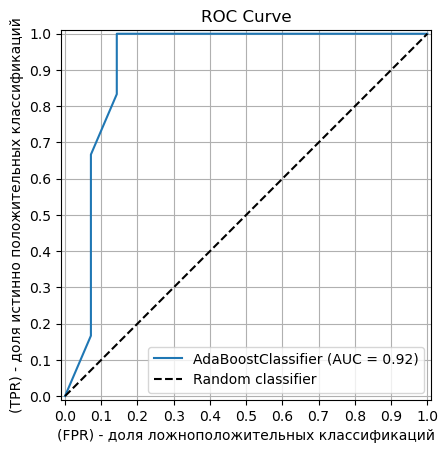

In [40]:
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(model_AdaBoostClassifier, x_test, y_test)
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')  # Диагональ (случайное угадывание)
plt.xlabel('(FPR) - доля ложноположительных классификаций')
plt.ylabel('(TPR) - доля истинно положительных классификаций')
plt.title('ROC Curve')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.legend()
plt.grid()
plt.show()

AUC: 0.9167 - отличное качество модели


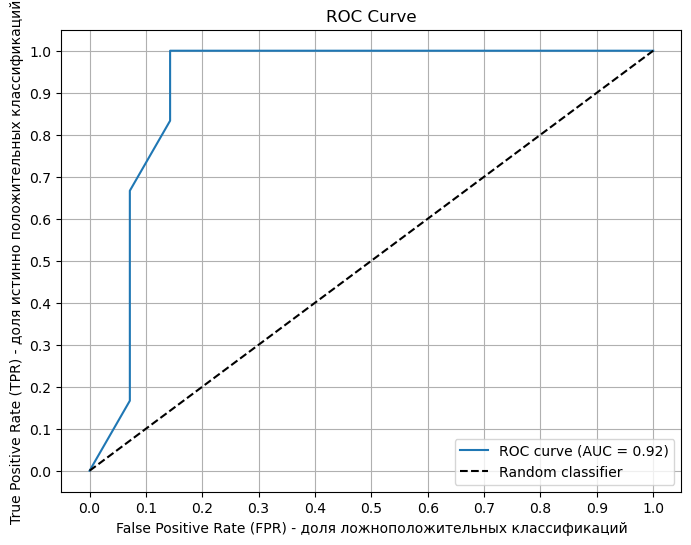

In [41]:
# Построение ROC-кривой
fpr, tpr, thresholds = roc_curve(y_test.astype(int), y_pred_proba)
auc_value = auc(fpr, tpr)
print(f"AUC: {auc_value:.4f} - отличное качество модели")
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_value:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')  # Диагональ (случайное угадывание)
plt.xlabel('False Positive Rate (FPR) - доля ложноположительных классификаций')
plt.ylabel('True Positive Rate (TPR) - доля истинно положительных классификаций')
plt.title('ROC Curve')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.legend()
plt.grid(True)
plt.show()

In [42]:
def youden_index(y_true, y_scores):
    """
    Вычисляет индекс Юдена для заданных истинных меток и предсказанных вероятностей.
    
    Параметры:
    - y_true: истинные метки (0 или 1)
    - y_scores: предсказанные вероятности класса 1
    
    Возвращает:
    - max_j: максимальное значение индекса Юдена
    - optimal_threshold: порог, дающий max_j
    - j_values: массив значений J для всех порогов
    - thresholds: массив порогов
    """
    # Получаем TPR и FPR для разных порогов
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    
    # Вычисляем специфичность (TNR = 1 - FPR)
    tnr = 1 - fpr

    # Индекс Юдена
    j_values = tpr + tnr - 1

    # Находим максимум и соответствующий порог
    max_j = np.max(j_values)
    optimal_idx = np.argmax(j_values)
    optimal_threshold = thresholds[optimal_idx]

    return max_j, optimal_threshold, j_values, thresholds

max_j, opt_thresh, j_vals, threshs = youden_index(y_test.astype(int), y_pred_proba)

print(f"Максимальный индекс Юдена: {max_j:.3f}")
print(f"Оптимальный порог: {opt_thresh:.3f}")

Максимальный индекс Юдена: 0.857
Оптимальный порог: 0.524


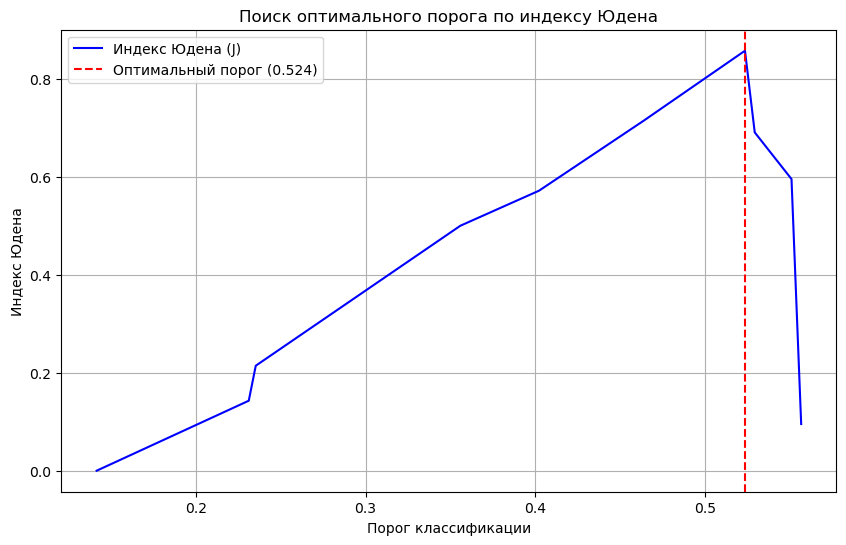

In [43]:
plt.figure(figsize=(10, 6))
plt.plot(threshs, j_vals, label='Индекс Юдена (J)', color='blue')
plt.axvline(x=opt_thresh, color='red', linestyle='--', 
            label=f'Оптимальный порог ({opt_thresh:.3f})')
plt.xlabel('Порог классификации')
plt.ylabel('Индекс Юдена')
plt.title('Поиск оптимального порога по индексу Юдена')
plt.legend()
plt.grid(True)
plt.show()

Интерпретация результатов
- J = 1 — идеальная модель (100 % sensitivity и 100 % specificity).
- J > 0.5 — хорошая модель.
- J ≈ 0 — модель не лучше случайного угадывания.
- J < 0 — модель работает хуже случайного (возможно, ошибка в знаках).

Индекс Юдена полезен:
- при несбалансированных классах;
- когда важно сбалансировать чувствительность и специфичность;
- для автоматического подбора порога классификации.

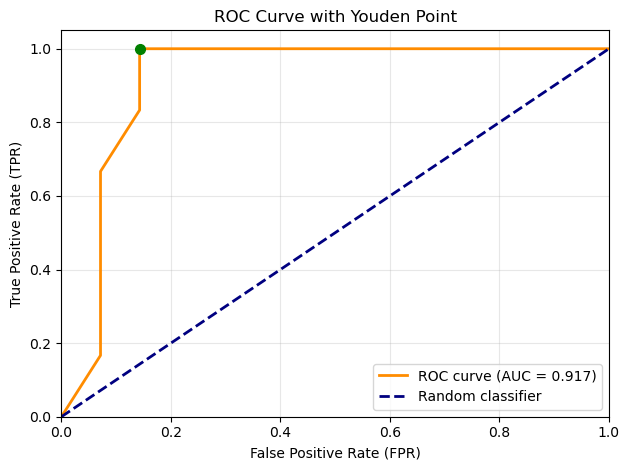

AUC: 0.917
Оптимальный порог по критерию Юдена: 0.524
TPR в точке Юдена: 1.000
FPR в точке Юдена: 0.143


In [44]:
j_scores = tpr - fpr  # J = TPR − FPR
j_optimal_idx = np.argmax(j_scores)
j_optimal_threshold = thresholds[j_optimal_idx]
j_fpr = fpr[j_optimal_idx]
j_tpr = tpr[j_optimal_idx]
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random classifier')
plt.plot(j_fpr, j_tpr, color = 'green', marker='o', markersize=7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve with Youden Point')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"AUC: {roc_auc:.3f}")
print(f"Оптимальный порог по критерию Юдена: {j_optimal_threshold:.3f}")
print(f"TPR в точке Юдена: {j_tpr:.3f}")
print(f"FPR в точке Юдена: {j_fpr:.3f}")

Оптимальный порог по Критерию Юдена - это самое большое расстояние от ROC-кривой до случайной (пунктир на графике).

---

# PrecisionRecallDisplay: построение и интерпретация графика

##### Как читать кривую:
Верхний правый угол (Precision ≈ 1, Recall ≈ 1) — идеальный классификатор: находит почти все положительные объекты и почти не ошибается.\
Нижний левый угол (Precision ≈ 0, Recall ≈ 0) — плохой классификатор: пропускает большинство положительных объектов и часто ошибается.\
Форма кривой:\
Крутая начальная часть — модель хорошо работает при строгих порогах (высокая точность, но низкая полнота).\
Пологий спад — баланс между точностью и полнотой сохраняется при снижении порога.\
Резкий обвал — при небольшом снижении порога точность резко падает (много ложных срабатываний).\
Точка с Recall = 1 (крайняя правая) — модель находит все положительные объекты, но точность может быть низкой (много FP).\
Точка с Precision = 1 (верхняя) — все предсказанные положительные объекты верны, но полнота может быть низкой (много FN).

График Precision-Recall (PR-кривая), создаваемый с помощью PrecisionRecallDisplay.from_predictions, визуализирует зависимость 
точности (Precision) от полноты (Recall) при различных пороговых значениях классификации. Этот инструмент особенно полезен для оценки 
моделей в условиях дисбаланса классов, когда один класс значительно преобладает над другим. 

Основные компоненты графика:
- Ось X (Recall, полнота): показывает долю истинно положительных случаев, которые модель правильно идентифицировала. Recall рассчитывается как отношение истинно положительных примеров (TP) 
к сумме истинно положительных и ложноотрицательных примеров (TP + FN). Высокий Recall означает, что модель хорошо находит положительные случаи, но может допускать больше ложных срабатываний. 
- Ось Y (Precision, точность): отражает долю правильно классифицированных положительных случаев среди всех предсказанных положительных. Precision рассчитывается как отношение истинно положительных
примеров (TP) к сумме истинно положительных и ложноположительных примеров (TP + FP). Высокая Precision указывает на то, что модель делает мало ложных положительных предсказаний. 
- Кривая: отображает, как меняются Precision и Recall при изменении порога классификации. Обычно при увеличении Recall (за счёт снижения порога) Precision уменьшается, так как модель начинает
классифицировать больше объектов как положительные, включая ложные срабатывания. 
- Площадь под кривой (AUC-PR): количественная метрика, которая оценивает способность модели различать классы. Чем выше AUC-PR, тем лучше модель справляется с задачей. Значение 1 указывает на идеальную 
модель, 0 — на случайное угадывание. 

Интерпретация графика
- Идеальная модель: кривая стремится к верхнему правому углу графика, где и Precision, и Recall близки к 1. Это означает, что модель точно идентифицирует положительные случаи, минимизируя ложные срабатывания и пропуски. 
- Случайные предсказания: кривая будет близка к диагонали от (0,0) до (1,1), особенно если классы сильно несбалансированы. В таком случае модель не демонстрирует значимого улучшения по сравнению с случайным угадыванием. 
- Слабая модель: кривая расположена ближе к нижнему левому углу, что указывает на низкую способность модели выявлять положительные случаи. 
- Выбор порога классификации: график помогает определить оптимальный порог, балансирующий между Precision и Recall в зависимости от задачи. Например, в медицине может быть критично минимизировать ложные отрицания (высокие Recall), тогда как в фильтрации спама важнее избежать ложных срабатываний (высокая Precision).

Сравнение с ROC-кривой:
    В отличие от ROC-кривой, которая учитывает как положительные, так и отрицательные классы, PR-кривая фокусируется только на положительном классе. Это делает её более подходящей для задач с дисбалансом классов, где важно оценить, как модель работает с редким классом.


График, построенный с помощью метода PrecisionRecallDisplay.from_predictions, показывает баланс между точностью Precision
(how many predicted positives are true positives) и полнотой Recall (how many true positives are correctly identified) для разных порогов. 

Некоторые особенности интерпретации:
- Каждый точка на кривой соответствует конкретному порогу классификации. 
- По мере уменьшения порога больше образцов классифицируются как положительные, увеличивая полноту, но часто уменьшая точность. 
- По мере увеличения порога происходит обратное. 
- Средняя точность (AP) summarizes график как взвешенное среднее точности, достигнутой при каждом пороге, с увеличением полноты от предыдущего порога в качестве веса.


TP (True Positive - верно классифицированные положительные объект. \
FN (False Negative)- пропущенные положительные объекты (ошибочно отнесены к отрицательным).\
FP (False Positive) - ошибочно названные положительными объекты (на самом деле отрицательные).\
TN (True Negative) - верно предсказанный отрицательный класс.

#### Что показывают оси графика:

Ось X (горизонтальная) — Recall (полнота, чувствительность): доля верно обнаруженных положительных объектов среди всех реальных положительных объектов.

Формула: Recall= TP/(TP+FN), где

TP (True Positive) — верно классифицированные положительные объекты,
FN (False Negative) — пропущенные положительные объекты (ошибочно отнесены к отрицательным).

Ось Y (вертикальная) — Precision (точность): доля верно классифицированных положительных объектов среди всех объектов, названных положительными.

Формула: Precision= TP/(TP+FP), где

FP (False Positive) — ошибочно названные положительными объекты (на самом деле отрицательные).

<Figure size 1000x600 with 0 Axes>

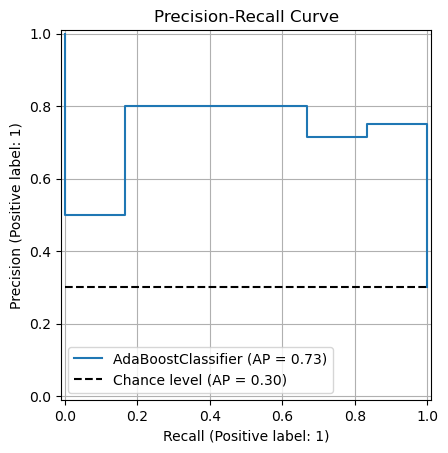

In [45]:
# Построение PR‑кривой
plt.figure(figsize=(10, 6))
disp = PrecisionRecallDisplay.from_predictions(y_test.to_numpy().astype(int), y_pred_proba, pos_label=1, plot_chance_level = True, 
    name = 'AdaBoostClassifier',  drop_intermediate = False, despine = False)
plt.title("Precision-Recall Curve") # plot_chance_level - линия уровня вероятности. Уровень вероятности — 
                                    # это распространённость положительного класса, вычисленная из данных, переданных во время вызова метода
plt.grid()
plt.show()

<Figure size 1000x600 with 0 Axes>

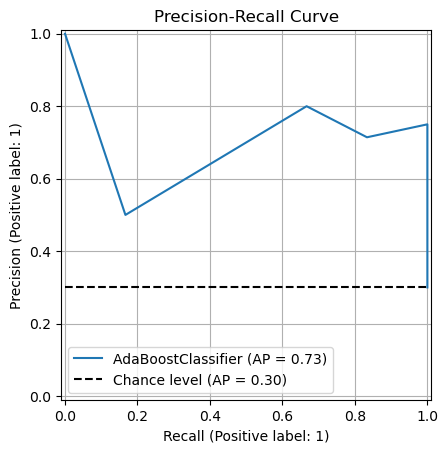

In [46]:
# Построение PR‑кривой
plt.figure(figsize=(10, 6))
disp = PrecisionRecallDisplay.from_predictions(y_test.astype(int), y_pred_proba, pos_label=1, plot_chance_level = True, drawstyle="default",
    name = 'AdaBoostClassifier',  drop_intermediate = False, despine = False)
plt.title("Precision-Recall Curve") # plot_chance_level - линия уровня вероятности. Уровень вероятности — 
                                    # это распространённость положительного класса, вычисленная из данных, переданных во время вызова метода
plt.grid()
plt.show()

### Расчет AP (интеграл под кривой PR):

In [47]:
y_test_1 = y_test.astype(int)
AP = average_precision_score(y_test_1, y_pred_proba) # AP — интеграл под кривой PR. Чем выше AP, тем лучше модель в целом.
print (f' AP (Средняя точность) = {AP:.2f}')

 AP (Средняя точность) = 0.73


In [48]:
precision, recall, _ = precision_recall_curve(y_test_1, y_pred_proba)
auc_score = auc(recall, precision)
print(f"AUC-PR (площадь под кривой): {auc_score:.4f}")

AUC-PR (площадь под кривой): 0.6982


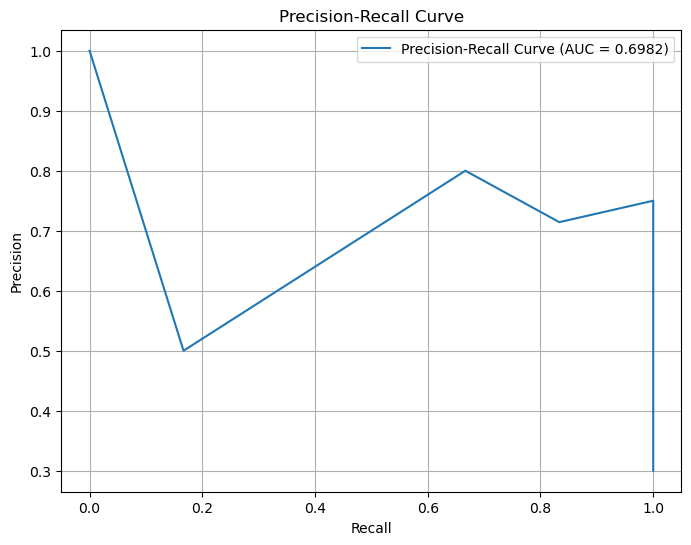

In [49]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {auc_score:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

## Точность для несбалансированных классов:

В отличие от обычной точности (accuracy), которая может быть обманчиво высокой на несбалансированных данных, balanced_accuracy:

- даёт равный вес всем классам;
- не зависит от пропорций классов в выборке;
- лучше отражает реальную способность модели распознавать все классы.

In [50]:
y_pred_1 = y_pred.astype(int)
y_pred_1

array([0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0])

In [51]:
acc_balanced = balanced_accuracy_score(y_test.astype(int), y_pred_1) # для несбалансированных данных
print(f'Точность (accuracy) для несбалансированных классов: {acc_balanced:.2f}')

Точность (accuracy) для несбалансированных классов: 0.93


## Проверка дисбаланса классов: 

In [52]:
count_values = db_logreg['Score'].value_counts()
count_values_ = db_logreg['Score'].value_counts(normalize=True) # в долях (процентах)
print(count_values, count_values_) # несбалансированные классы

Score
0    138
1     62
Name: count, dtype: int64 Score
0    0.69
1    0.31
Name: proportion, dtype: float64


## Точность на тестовой и обучающей выборках:

Что возвращает метод Score:
Число типа float в диапазоне [0.0, 1.0].
1.0 — все объекты классифицированы верно.
0.0 — все предсказания ошибочны.

Для оценки степени переобучения используют Accuracy (точность) — показывает долю правильных предсказаний модели относительно общего числа предсказаний. Если модель показывает <u><b>высокий результат  при обучении</b></u>, но <u><b>на новых данных качество резко падает </b></u>, это говорит о переобучении.

In [54]:
score = model_AdaBoostClassifier.score(x_test, y_test) # Точность на тестовой выборке
score_2 = model_AdaBoostClassifier.score(x_train, y_train) # Точность на обучающей выборке
print(f'Точность на тестовой выборке: {score:.2f}')
print(f'Точность на обучающей выборке: {score_2:.2f}')

Точность на тестовой выборке: 0.90
Точность на обучающей выборке: 0.87


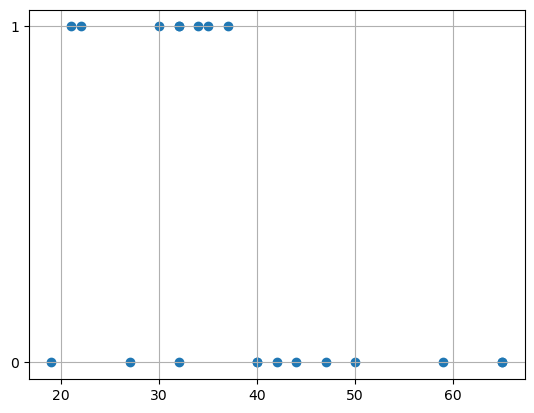

In [55]:
plt.scatter(x_test[:, 0], model_AdaBoostClassifier.predict(x_test))
plt.grid()
plt.show()

<Figure size 1200x600 with 0 Axes>

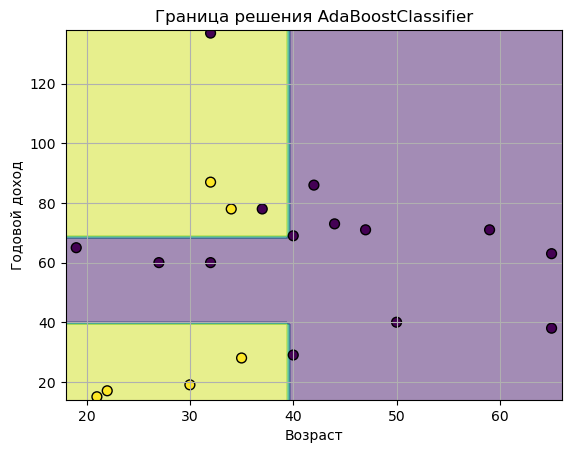

In [57]:
# Визуализация
x = x_test
x = np.asarray(x)
y = y_test.astype(int)

# Визуализируем границу решения
plt.figure(figsize=(12, 6))
disp = DecisionBoundaryDisplay.from_estimator(model_AdaBoostClassifier, x, response_method="predict", 
    alpha=0.5,
    plot_method = 'contourf', 
    xlabel="Возраст",
    ylabel="Годовой доход")

disp.ax_.scatter(x[:, 0], x[:, 1], c=y, edgecolor="k", s=50)
plt.title("Граница решения AdaBoostClassifier")
plt.grid()
plt.show()

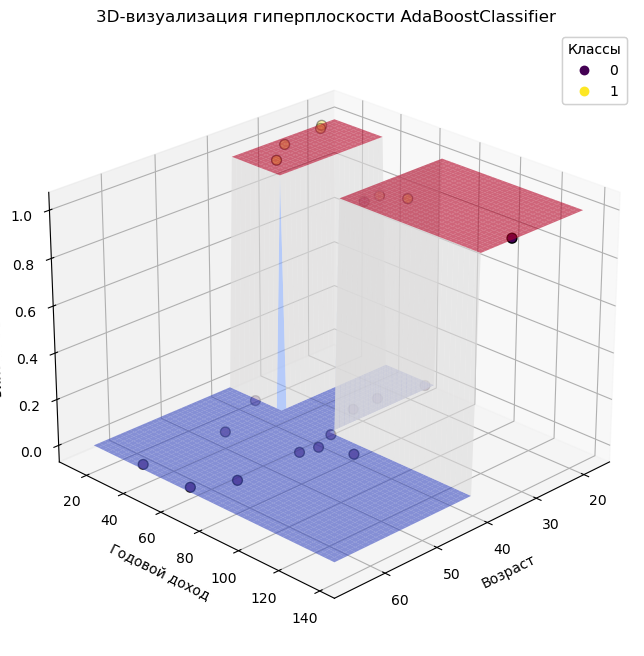

In [58]:
# Определяем границы для сетки
x_min, x_max = x[:, 0].min() - 1, x[:, 0].max() + 1
y_min, y_max = x[:, 1].min() - 1, x[:, 1].max() + 1

# Создаём сетку
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 50),
                   np.linspace(y_min, y_max, 50))

# Вычисляем значения функции решения на сетке
Z = model_AdaBoostClassifier.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Рисуем поверхность гиперплоскости (Z = 0 — граница решения)
surf = ax.plot_surface(xx, yy, Z, alpha=0.6, cmap='coolwarm',
                       linewidth=0, antialiased=True)

# # Добавляем линию границы решения (Z = 0)
# ax.contour(xx, yy, Z, levels=[0], colors='black', linewidths=2)

# Рисуем точки данных
scatter = ax.scatter(x[:, 0], x[:, 1], model_AdaBoostClassifier.predict(x).astype(int),
                   c=y, cmap='viridis', s=50, edgecolors='k')

# Подписи осей
ax.set_xlabel('Возраст')
ax.set_ylabel('Годовой доход')
ax.set_zlabel('Функция решения')
ax.set_title('3D-визуализация гиперплоскости AdaBoostClassifier')
ax.view_init(elev=25, azim=45)
# Легенда
legend = ax.legend(*scatter.legend_elements(), title="Классы")
ax.add_artist(legend)
plt.show()

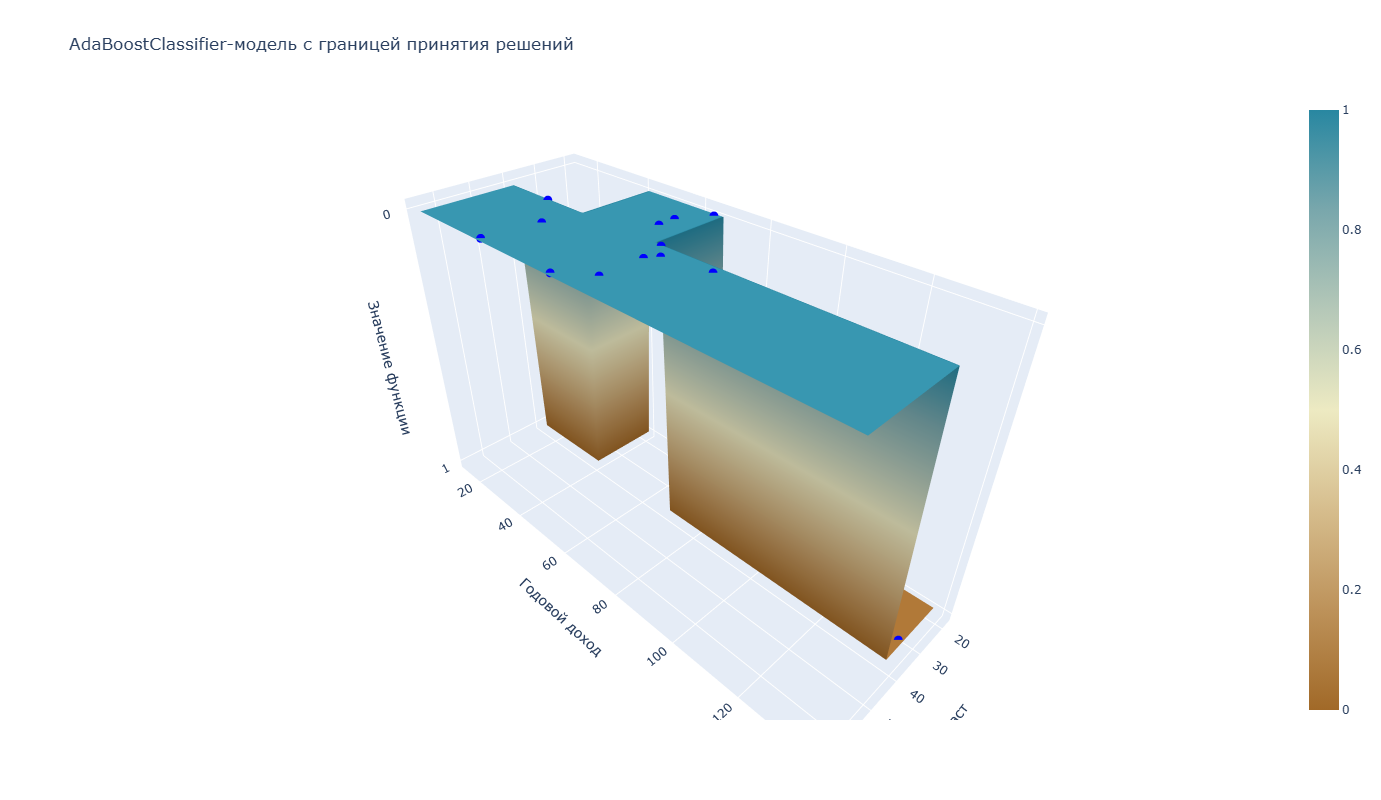

In [60]:
# Визуализация
x1 = x_test
x1 = np.asarray(x1)
y1 = y_test.astype(int)

# Определяем границы для сетки
x_min, x_max = x1[:, 0].min() - 1, x1[:, 0].max() + 1
y_min, y_max = x1[:, 1].min() - 1, x1[:, 1].max() + 1

# Создаём сетку
xx1, yy1 = np.meshgrid(np.linspace(x_min, x_max, 50),
                   np.linspace(y_min, y_max, 50))

# Вычисляем значения функции решения на сетке
Z = model_AdaBoostClassifier.predict(np.c_[xx1.ravel(), yy1.ravel()])
Z = Z.reshape(xx1.shape)

fig = go.Figure(data=[go.Surface(z=Z, x=xx1[0, :], y=yy1[:, 0], opacity=1.0, colorscale='Earth')])
fig.update_layout(title='AdaBoostClassifier-модель с границей принятия решений')
fig.add_trace(go.Scatter3d(x = x1[:, 0], y = x1[:, 1], z = model_AdaBoostClassifier.predict(x_test), mode='markers',  marker=dict(
        size=5,
        color=y,  # цвет по классу
        colorscale='Picnic',
        showscale=False
    )))
fig.update_layout(
    width=1200,
    height=800,
    scene=dict(
        # Названия осей
    xaxis_title='Возраст',
    yaxis_title='Годовой доход',
    zaxis_title='Значение функции'
))
fig.show()

### Доступные встроенные палитры:
Blackbody, Bluered, Blues, Cividis, Earth, Electric, Greens, Greys, Hot, Jet, Picnic, Portland, Rainbow, RdBu, Reds, Viridis, YlGnBu, YlOrRd

---

### Вычисление порога классификации:
#### Выбор порога — это компромисс между:

<p><strong><u> Precision </u></strong> (точность: сколько из предсказанных «1» действительно «1»); отвечает на вопрос <em>"Насколько я могу доверять положительным предсказаниям модели?"</em></p>
<p><strong><u> Recall </u></strong>(полнота: какую долю реальных «1» мы нашли). отвечает на вопрос <em>"Находит ли модель все положительные случаи?"</em></p>

In [61]:
# Сетка порогов от 0.1 до 0.9 с шагом 0.05
thresholds = np.arange(0.1, 1.0, 0.05)


results = []
for th in thresholds:
    y_pred = (y_pred_proba >= th).astype(int)
    
    precision = precision_score(y_test_1, y_pred)
    recall = recall_score(y_test_1, y_pred)
    f1 = f1_score(y_test_1, y_pred)
    
    results.append({
        'threshold': th,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

# Преобразуем в DataFrame для удобства
results_df = pd.DataFrame(results)
print(results_df)

    threshold  precision    recall        f1
0        0.10   0.300000  1.000000  0.461538
1        0.15   0.333333  1.000000  0.500000
2        0.20   0.333333  1.000000  0.500000
3        0.25   0.461538  1.000000  0.631579
4        0.30   0.461538  1.000000  0.631579
5        0.35   0.461538  1.000000  0.631579
6        0.40   0.500000  1.000000  0.666667
7        0.45   0.600000  1.000000  0.750000
8        0.50   0.750000  1.000000  0.857143
9        0.55   0.800000  0.666667  0.727273
10       0.60   0.000000  0.000000  0.000000
11       0.65   0.000000  0.000000  0.000000
12       0.70   0.000000  0.000000  0.000000
13       0.75   0.000000  0.000000  0.000000
14       0.80   0.000000  0.000000  0.000000
15       0.85   0.000000  0.000000  0.000000
16       0.90   0.000000  0.000000  0.000000
17       0.95   0.000000  0.000000  0.000000


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.

C:\ProgramData\anaconda3\Lib\site-pa

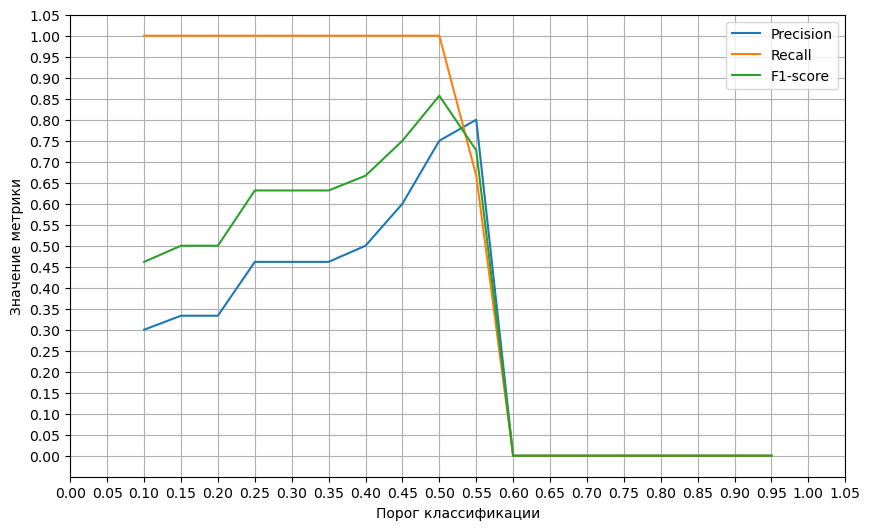

In [62]:
# Визуализация порога классификации
plt.figure(figsize=(10, 6))
plt.plot(results_df['threshold'], results_df['precision'], label='Precision')
plt.plot(results_df['threshold'], results_df['recall'], label='Recall')
plt.plot(results_df['threshold'], results_df['f1'], label='F1-score')
plt.xlabel('Порог классификации')
plt.ylabel('Значение метрики')
plt.legend()
plt.xticks(np.arange(0, 1.1, 0.05))
plt.yticks(np.arange(0, 1.1, 0.05))
plt.grid(True)
plt.show()

In [63]:
# Максимальный F1‑score
best_th = results_df.loc[results_df['f1'].idxmax(), 'threshold']
print(f"Оптимальный порог (по F1): {best_th:.4f}")

Оптимальный порог (по F1): 0.5000


In [64]:
# Минимальный Recall ≥ целевого уровня
target_recall = 0.8
feasible = results_df[results_df['recall'] >= target_recall]
best_th = feasible['threshold'].min()
print(f"Порог для Recall ≥ {target_recall}: {best_th}")

Порог для Recall ≥ 0.8: 0.1


In [65]:
# Баланс Precision и Recall (точка, где они близки)
results_df['diff'] = abs(results_df['precision'] - results_df['recall'])
best_th = results_df.loc[results_df['diff'].idxmin(), 'threshold']
print(f"Порог с минимальным разбросом Precision и Recall: {best_th:.2f}")

Порог с минимальным разбросом Precision и Recall: 0.60


In [66]:
OPTIMAL_THRESHOLD = 0.5 # уменьшив порог, увеличили количество "1", т.е. долю получения положительных исходов (и наоборот). 
# Проверка предсказаний с учетом оптимального порога OPTIMAL_THRESHOLD (можем задавать свой порог)
new_data3 = [[39, 17]]
y_new_proba = model_AdaBoostClassifier.predict_proba(new_data3)[:, 1]
y_new_pred = (y_new_proba.astype(float) >= OPTIMAL_THRESHOLD).astype(int)
y_new_pred

array([1])

In [67]:
OPTIMAL_THRESHOLD = 0.5 # уменьшив порог, увеличили количество "1", т.е. долю получения положительных исходов (и наоборот). 
# Проверка предсказаний с учетом оптимального порога OPTIMAL_THRESHOLD (можем задавать свой порог)
new_data3 = [[40, 17]]
y_new_proba = model_AdaBoostClassifier.predict_proba(new_data3)[:, 1]
y_new_pred = (y_new_proba.astype(float) >= OPTIMAL_THRESHOLD).astype(int)
y_new_pred

array([0])